# Новости + рынок: датасет для *News embeddings for finance prediction*

Дневная частота, единый торговый календарь NYSE, период **1990 → сегодня**.

| Файл (`data/processed/`) | Содержимое |
|---|---|
| `news_articles.parquet` | все новостные статьи NYT (заголовок, аннотация, лид, рубрика, ключевые слова, ...), `pub_time_utc`, флаг `is_finance`, **`trading_date`** — торговый день, к окну которого относится новость (прошлое закрытие 16:00 ET → закрытие 16:00 ET) |
| `market_prices.parquet` | дневные OHLCV для 29 инструментов (S&P 500 и др. индексы, секторные ETF, доходности Treasuries, VIX, облигационные ETF, FX, сырьё), Yahoo Finance |
| `prices_wide.parquet` | adjusted close: торговые дни × тикеры — наблюдаемые цены \(p_t\) |
| `daily.parquet` | одна строка на торговый день: S&P 500, число статей, склеенный текст финансовых новостей — вход для \(\varepsilon_t\) |
| `meta.json` | источники, период, покрытие, метрики |

Источники и логика сборки — в `scripts/` (см. `README.md`). Первая ячейка при первом запуске скачивает сырые данные (~1.3 ГБ, 10–15 мин) и собирает датасет; дальше использует готовые файлы из `data/processed/`.

In [1]:
from scripts.build_dataset import ensure_dataset, load

paths = ensure_dataset()                       # скачать и собрать при первом запуске, иначе переиспользовать (force=True — пересобрать)
data = load(paths)
news, prices, prices_wide, daily, meta = (data[k] for k in ("news", "prices", "prices_wide", "daily", "meta"))
{k: str(v) for k, v in paths.items()}

18:42:57 INFO scripts.build_dataset: dataset found in C:\Users\mperi\news-embed-for-finance-prediction\data\processed - reusing (pass force=True to rebuild)


{'news': 'C:\\Users\\mperi\\news-embed-for-finance-prediction\\data\\processed\\news_articles.parquet',
 'prices': 'C:\\Users\\mperi\\news-embed-for-finance-prediction\\data\\processed\\market_prices.parquet',
 'prices_wide': 'C:\\Users\\mperi\\news-embed-for-finance-prediction\\data\\processed\\prices_wide.parquet',
 'daily': 'C:\\Users\\mperi\\news-embed-for-finance-prediction\\data\\processed\\daily.parquet',
 'meta': 'C:\\Users\\mperi\\news-embed-for-finance-prediction\\data\\processed\\meta.json'}

In [2]:
import pandas as pd
pd.set_option("display.max_colwidth", 70, "display.width", 180)

p, n = meta["period"], meta["news"]
print(f"период      : {p['start']} → {p['end']}  ({p['trading_days']} торговых дней)")
print(f"новости     : {n['articles']:,} статей, из них финансовых {n['finance_articles']:,} "
      f"({n['articles_per_trading_day']} / {n['finance_articles_per_trading_day']} на торговый день)")
print(f"источники   : {n['sources']}")
print(f"рынок       : {len(meta['market']['tickers'])} тикеров, {len(prices):,} строк, источник {meta['market']['source']}")
for name, df in (("news", news), ("prices", prices), ("prices_wide", prices_wide), ("daily", daily)):
    print(f"\n{name:12s}{df.shape}  " + ", ".join(df.columns[:14]) + (" ..." if df.shape[1] > 14 else ""))
news[["pub_time_utc", "trading_date", "headline", "section", "news_desk", "is_finance", "flag_source"]].sample(5, random_state=1)

период      : 2000-01-03 → 2025-12-31  (6539 торговых дней)
новости     : 1,238,053 статей, из них финансовых 360,666 (189.3 / 55.2 на торговый день)
источники   : ['kaggle:aryansingh0909/nyt-articles-21m-2000-present (complete months: 282)', 'hf:bguzzo2k/nyt_100y_news_headlines (110246 articles added)']
рынок       : 29 тикеров, 185,396 строк, источник yahoo finance (yfinance)

news        (1238053, 17)  article_id, pub_time_utc, headline, abstract, lead_paragraph, section, subsection, news_desk, type_of_material, document_type, source, keywords, word_count, web_url ...

prices      (185396, 8)  date, ticker, open, high, low, close, adj_close, volume

prices_wide (6539, 29)  ^GSPC, ^DJI, ^IXIC, ^RUT, SPY, QQQ, XLF, XLK, XLE, XLV, XLY, XLP, XLI, XLB ...

daily       (6539, 6)  date, spx_close, spx_logret, n_articles, n_finance, finance_text


,pub_time_utc,trading_date,headline,section,news_desk,is_finance,flag_source
1008972,2018-04-12 12:24:19+00:00,2018-04-12,Legal Aid Demands Rebates for Nycha Tenants Left in the Cold,New York,Metro,False,metadata
707274,2011-05-26 03:15:21+00:00,2011-05-26,"Plane Crashes in New Delhi, Killing 10",World,Foreign,False,metadata
1183421,2024-02-25 04:43:28+00:00,2024-02-26,Delegate Math and the Futility of Haley’s Challenge to Trump,,,False,text_model
288755,2005-06-09 05:00:00+00:00,2005-06-09,World Briefing | Asia: India: Top Sikh Militant Held In Cinema Blasts,World,Foreign Desk,False,metadata
20759,2000-06-09 05:00:00+00:00,2000-06-09,WORLD BRIEFING,World,Foreign Desk,False,metadata


## Покрытие по годам

In [3]:
year = news["trading_date"].dt.year
by_year = pd.DataFrame({
    "trading_days": daily.groupby(daily["date"].dt.year).size(),
    "articles": news.groupby(year).size(),
    "finance": news[news.is_finance].groupby(year[news.is_finance]).size(),
    "finance_per_day": (news[news.is_finance].groupby(year[news.is_finance]).size()
                        / daily.groupby(daily["date"].dt.year).size()).round(1),
    "text_model_share": news.groupby(year)["flag_source"].apply(lambda s: round((s == "text_model").mean(), 2)),
})
by_year.index.name = "year"
display(by_year)

cov = pd.DataFrame(meta["market"]["tickers"]).T
cov

,trading_days,articles,finance,finance_per_day,text_model_share
year,,,,,
2000,252,49260,17362,68.9,0.00
2001,248,56842,18978,76.5,0.00
2002,252,55586,19420,77.1,0.00
2003,252,54421,18980,75.3,0.00
2004,252,50659,16788,66.6,0.00
2005,252,48238,13309,52.8,0.00
2006,251,84194,29051,115.7,0.00
2007,251,59715,21021,83.7,0.00
2008,253,69303,24832,98.2,0.00


,name,group,first,last,n_obs
LQD,iShares IG Corporate Bond ETF,bond_etf,2002-07-30,2025-12-31,5895
TLT,iShares 20+ Year Treasury ETF,bond_etf,2002-07-30,2025-12-31,5895
HYG,iShares High Yield Corporate Bond ETF,bond_etf,2007-04-11,2025-12-31,4713
QQQ,Invesco Nasdaq-100 ETF,broad_etf,2000-01-03,2025-12-31,6539
SPY,SPDR S&P 500 ETF,broad_etf,2000-01-03,2025-12-31,6539
CL=F,WTI crude oil futures,commodity,2000-08-23,2025-12-31,6367
GC=F,Gold futures,commodity,2000-08-30,2025-12-31,6359
HG=F,Copper futures,commodity,2000-08-30,2025-12-31,6363
^DJI,Dow Jones Industrial Average,equity_index,2000-01-03,2025-12-31,6539
^GSPC,S&P 500,equity_index,2000-01-03,2025-12-31,6539


## Динамика: поток новостей и S&P 500

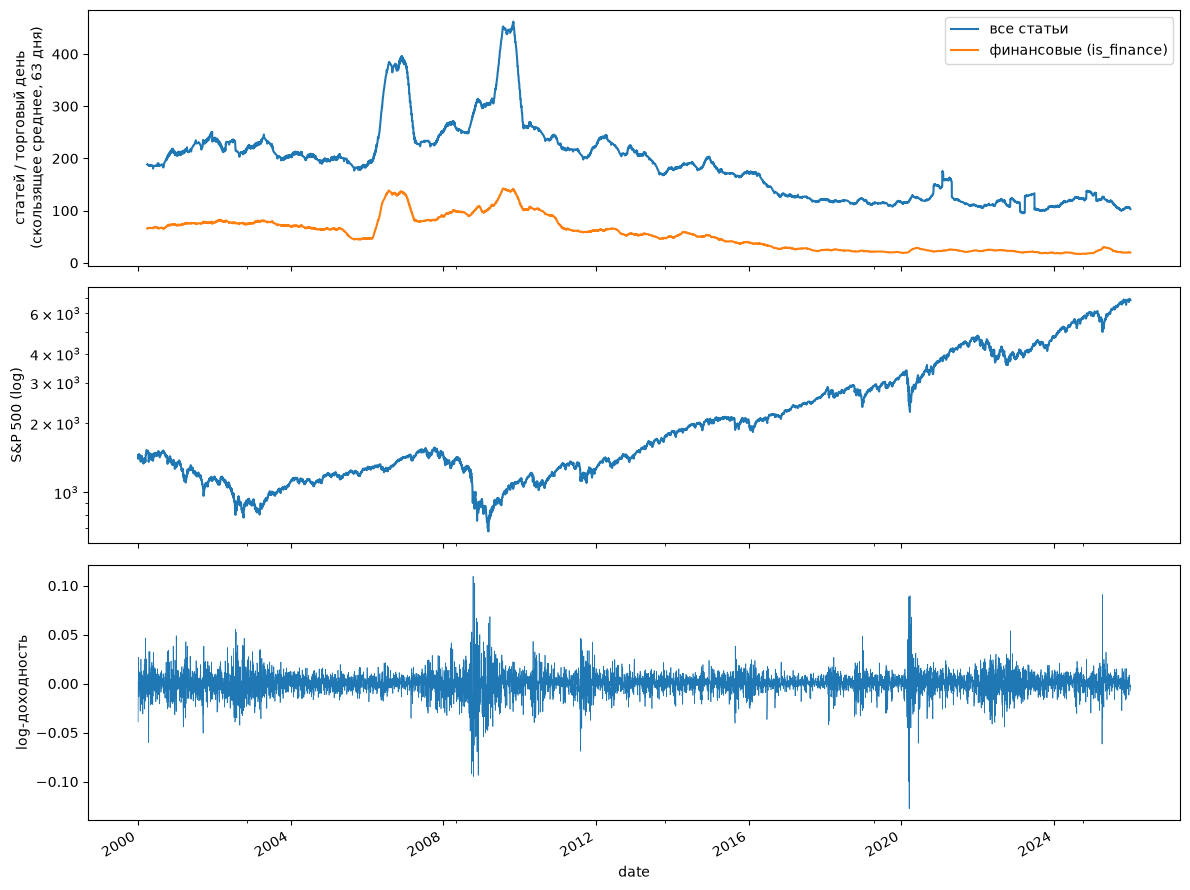

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
d = daily.set_index("date")
d["n_articles"].rolling(63).mean().plot(ax=ax[0], label="все статьи")
d["n_finance"].rolling(63).mean().plot(ax=ax[0], label="финансовые (is_finance)")
ax[0].set_ylabel("статей / торговый день\n(скользящее среднее, 63 дня)"); ax[0].legend()
d["spx_close"].plot(ax=ax[1], logy=True); ax[1].set_ylabel("S&P 500 (log)")
d["spx_logret"].plot(ax=ax[2], lw=0.5); ax[2].set_ylabel("log-доходность")
plt.tight_layout()

## Пример: окно одного торгового дня

In [5]:
day = daily.loc[daily["spx_logret"].abs().idxmax(), "date"]            # день с максимальным |движением|
win = news[(news.trading_date == day) & news.is_finance].sort_values("pub_time_utc")
print(f"{day.date()}  S&P 500 log-return = {daily.set_index('date').loc[day, 'spx_logret']:+.3f};  "
      f"{len(win)} финансовых статей в окне (прошлое закрытие → закрытие)")
print(f"публикации: {win.pub_time_utc.min()} → {win.pub_time_utc.max()}")
win[["pub_time_utc", "headline", "section"]].head(12)

2020-03-16  S&P 500 log-return = -0.128;  50 финансовых статей в окне (прошлое закрытие → закрытие)
публикации: 2020-03-13 22:11:53+00:00 → 2020-03-16 18:54:21+00:00


,pub_time_utc,headline,section
1065008,2020-03-13 22:11:53+00:00,Bill Gates Stepping Down From Microsoft’s Board,Technology
1065013,2020-03-13 22:59:13+00:00,Is There Really a Toilet Paper Shortage?,Business Day
1065015,2020-03-13 23:09:42+00:00,Stocks Surge After Trump Promises Speedier Coronavirus Testing,Business Day
1065027,2020-03-14 02:17:19+00:00,Fox Business Benches Trish Regan After Outcry Over Coronavirus Com...,Business Day
1065038,2020-03-14 09:00:18+00:00,"As China Cracks Down on Coronavirus Coverage, Journalists Fight Back",Business Day
1065040,2020-03-14 09:00:19+00:00,"He Has 17,700 Bottles of Hand Sanitizer and Nowhere to Sell Them",Technology
1065048,2020-03-14 12:39:51+00:00,Apple Closes Most of Its Stores for 2 Weeks,Technology
1065053,2020-03-14 14:34:44+00:00,"Trump Is Losing Money in the Markets, Too",Business Day
1065064,2020-03-14 15:54:57+00:00,Internet Providers Won’t Cut Off Users Over Unpaid Bills for 60 Days,Business Day
1065065,2020-03-14 16:31:49+00:00,Guyana Leader Set to Take New Term After a Vote Denounced as Flawed,World


## Проверки согласованности

In [6]:
from scripts.align import session_close_utc

cal = pd.DatetimeIndex(daily["date"])
close = pd.Series(session_close_utc(cal).tz_convert(None), index=cal)        # закрытие сессии, UTC
pub = news["pub_time_utc"].dt.tz_convert(None).to_numpy()
assert cal.equals(prices_wide.index) and cal.is_monotonic_increasing and cal.is_unique, "единый календарь"
assert (pub <= close.reindex(news["trading_date"]).to_numpy()).all(), "новость не позже закрытия своего дня"
prev_close = close.shift(1).reindex(news["trading_date"]).to_numpy()
assert (np.isnat(prev_close) | (pub > prev_close)).all(), "новость позже предыдущего закрытия"
assert news["article_id"].is_unique and news["headline"].str.len().gt(0).all()
assert prices_wide[meta["market"]["core_tickers"]].notna().mean().min() > 0.99, "ядро тикеров без пропусков"
assert daily["n_articles"].eq(0).sum() == 0, "каждый торговый день содержит новости"
print("OK:", len(cal), "торговых дней,", f"{len(news):,}", "статей,", prices_wide.shape[1], "тикеров;",
      f"пропуски adj_close в ядре: {prices_wide[meta['market']['core_tickers']].isna().mean().max():.2%}")

OK: 6539 торговых дней, 1,238,053 статей, 29 тикеров; пропуски adj_close в ядре: 0.46%


## Как использовать в модели

* \(\varepsilon_t\) — эмбеддинг новостей торгового дня \(t\): `daily.finance_text` (или `news.groupby("trading_date")` c нужным фильтром по `section`/`is_finance`);
* \(p_t\) — `np.log(prices_wide)` (adjusted close), доходности `np.log(prices_wide).diff()`;
* \(x_{t+1} = A x_t + \varepsilon_t\) оценивается на одном и том же индексе `daily.date`; новости внутри окна дня \(t\) публикуются **до** закрытия дня \(t\), поэтому утечки будущего нет.
* Пересборка/обновление: `python -m scripts.build_dataset --force`; с ключом `NYT_API_KEY` в `.env`/окружении последние месяцы берутся с полными метаданными из официального NYT Archive API.